In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
x_train = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

y_train = np.array([3, 5, 8, 12, 17, 23, 30, 38, 47, 57])

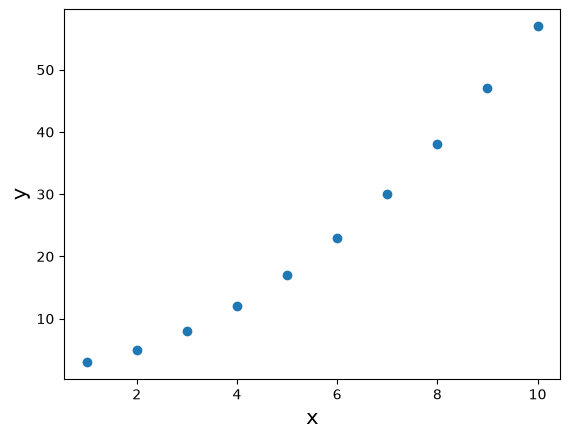

In [4]:
plt.scatter(x_train,y_train)
plt.ylabel('y', fontsize=15)
plt.xlabel('x', fontsize=15)

plt.show()

In [5]:
x_poly=np.column_stack((x_train,x_train**2))
print(x_poly)
print(x_poly.shape)

[[  1   1]
 [  2   4]
 [  3   9]
 [  4  16]
 [  5  25]
 [  6  36]
 [  7  49]
 [  8  64]
 [  9  81]
 [ 10 100]]
(10, 2)


In [6]:
def compute_prediction(x,w,b):
    return np.dot(x,w)+b
w = np.zeros(2)
b = 0

predictions = compute_prediction(x_poly, w, b)

print(predictions.shape)


(10,)


In [7]:
def compute_cost(x,y,w,b):
    m=x.shape[0]
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    cost=np.sum(error**2)/(2*m)
    return cost

In [8]:
def compute_gradient(x,y,w,b):
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    m=x.shape[0]
    dj_dw=(x.T @ error)/m
    dj_db=np.sum(error)/(m)
    return dj_dw,dj_db
w = np.zeros(2)
b = 0

dj_dw, dj_db = compute_gradient(
    x_poly, y_train, w, b
)

print("dj_dw:", dj_dw)
print("dj_dw shape:", dj_dw.shape)
print("dj_db:", dj_db)

dj_dw: [ -181.5 -1494.9]
dj_dw shape: (2,)
dj_db: -24.0


In [9]:
def gradient_descent(x,y,w,b,alpha,iterations):
    train_cost_history=[]
    for i in range(iterations):
        dj_dw,dj_db=compute_gradient(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        train_cost=compute_cost(x,y,w,b)
        
        train_cost_history.append(train_cost)
        
    return w,b,train_cost_history
w = np.zeros(2)
b = 0

w_final, b_final,cost_history = gradient_descent(
    x_poly,
    y_train,
    w,
    b,
    alpha=0.0001,
    iterations=1000
)

print("Final weights:", w_final)
print("Final bias:", b_final)
print("final cost:", cost_history[-1])

Final weights: [0.31276291 0.55109416]
Final bias: 0.11609095112899573
final cost: 1.096389930771816


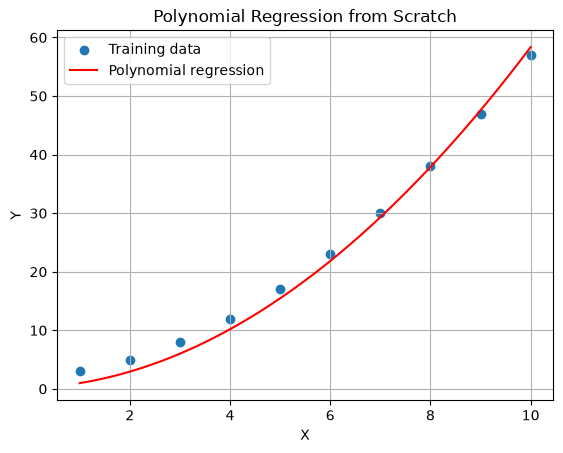

In [10]:

# Generate smooth x values for plotting
x_plot = np.linspace(x_train.min(), x_train.max(), 200)

# Create polynomial features for the new x values
X_plot = np.column_stack((x_plot, x_plot**2))

# Predict using our trained model
y_plot = compute_prediction(X_plot, w_final, b_final)

# Plot actual data and model predictions
plt.scatter(x_train, y_train, label="Training data")
plt.plot(x_plot, y_plot, color="red", label="Polynomial regression")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression from Scratch")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# compare ploynomial regression with ordinary linear regression 
X_linear = x_train.reshape(-1, 1)

w_linear = np.zeros(1)
b_linear = 0.

w_linear, b_linear,cost_history = gradient_descent(
    X_linear,
    y_train,
    w_linear,
    b_linear,
    alpha=0.01,
    iterations=10000
)

linear_cost = compute_cost(
    X_linear, y_train, w_linear, b_linear
)

polynomial_cost = compute_cost(
    x_poly, y_train, w_final, b_final
)

print("Linear regression cost:", linear_cost)
print("Polynomial regression cost:", polynomial_cost)

Linear regression cost: 6.599999999999999
Polynomial regression cost: 1.096389930771816


In [12]:
# Calculate mean and standard deviation
mean = np.mean(x_poly, axis=0)
std = np.std(x_poly, axis=0)

# Normalize features
X_poly_norm = (x_poly - mean) / std

print("Mean:", mean)
print("Standard deviation:", std)
print("Normalized features:\n", X_poly_norm)

Mean: [ 5.5 38.5]
Standard deviation: [ 2.87228132 32.4199013 ]
Normalized features:
 [[-1.5666989  -1.15669692]
 [-1.21854359 -1.06416117]
 [-0.87038828 -0.90993491]
 [-0.52223297 -0.69401815]
 [-0.17407766 -0.41641089]
 [ 0.17407766 -0.07711313]
 [ 0.52223297  0.32387514]
 [ 0.87038828  0.78655391]
 [ 1.21854359  1.31092318]
 [ 1.5666989   1.89698295]]


In [13]:
w_norm = np.zeros(X_poly_norm.shape[1])
b_norm = 0.

w_norm, b_norm,cost_history = gradient_descent(
    X_poly_norm,
    y_train,
    w_norm,
    b_norm,
    alpha=0.01,
    iterations=10000
)

print("Normalized weights:", w_norm)
print("Normalized bias:", b_norm)

print("Normalized cost:",
      compute_cost(X_poly_norm, y_train, w_norm, b_norm))

Normalized weights: [ 2.01612629 15.62996502]
Normalized bias: 23.999999999999826
Normalized cost: 0.008558053041969929


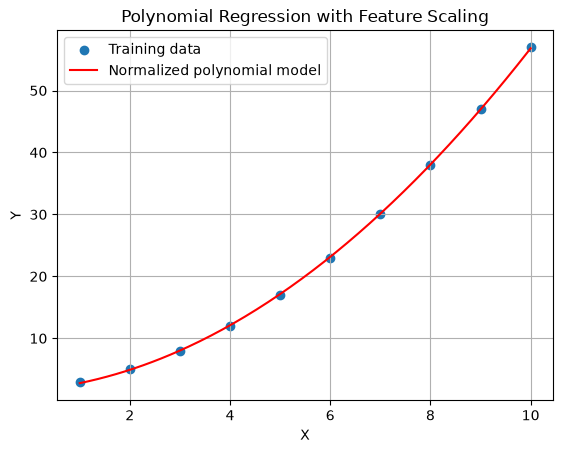

In [14]:
# Generate smooth x values
x_plot = np.linspace(x_train.min(), x_train.max(), 200)

# Create polynomial features
X_plot = np.column_stack((x_plot, x_plot**2))

# Apply the original training normalization parameters
X_plot_norm = (X_plot - mean) / std

# Predict using normalized weights
y_plot = compute_prediction(X_plot_norm, w_norm, b_norm)

# Plot
plt.scatter(x_train, y_train, label="Training data")
plt.plot(x_plot, y_plot, color="red", label="Normalized polynomial model")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression with Feature Scaling")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# Predictions from the unscaled model
y_pred_unscaled = compute_prediction(x_poly, w_final, b_final)

# Predictions from the scaled model
y_pred_scaled = compute_prediction(X_poly_norm, w_norm, b_norm)

print("Actual values:     ", y_train[:5])
print("Unscaled predictions:", y_pred_unscaled[:5])
print("Scaled predictions:  ", y_pred_scaled[:5])

print("Unscaled cost:", compute_cost(x_poly, y_train, w_final, b_final))
print("Scaled cost:", compute_cost(X_poly_norm, y_train, w_norm, b_norm))

Actual values:      [ 3  5  8 12 17]
Unscaled predictions: [ 0.97994802  2.94599342  6.01422713 10.18464918 15.45725954]
Scaled predictions:   [ 2.76220474  4.91046041  8.02293648 12.09963294 17.14054979]
Unscaled cost: 1.096389930771816
Scaled cost: 0.008558053041969929


In [21]:
w_new=w_norm/std
b_new=b_norm-((w_norm[0]*mean[0])/std[0])-(w_norm[1]*mean[1])/std[1]
print("w: ",w_new)
print("b: ",b_new)

w:  [0.70192508 0.4821102 ]
b:  1.5781694689151244


In [23]:
y_pred_converted = compute_prediction(x_poly, w_new, b_new)

print("Normalized predictions:", y_pred_scaled[:5])
print("Converted predictions:", y_pred_converted[:5])

print("Maximum prediction difference:",
      np.max(np.abs(y_pred_scaled - y_pred_converted)))

Normalized predictions: [ 2.76220474  4.91046041  8.02293648 12.09963294 17.14054979]
Converted predictions: [ 2.76220474  4.91046041  8.02293648 12.09963294 17.14054979]
Maximum prediction difference: 1.4210854715202004e-14
